# Classificação de Entregas (correta ou atraso) com Regressão Logística Simples

**Iniciação Científica** — *Introdução aos Paradigmas de Machine Learning por meio do Estudo,
Implementação e Avaliação de Algoritmos Clássicos*

- **Aluno:** Maurício Jampani de Souza
- **Orientador:** Prof. Me. Marcio Rodrigues Sabino
- **Dataset:** `dados_logistica.csv` — 42 pedidos
- **Área:** Análise e Desenvolvimento de Sistemas / Infraestrutura de TI

**Pergunta:** a antecedência com que um pedido é despachado ajuda a prever se ele chega na data correta?

---

## Estrutura

| Item | Conteúdo |
|---|---|
| **1 e 2** | O problema e o tipo de tarefa |
| **3** | Variáveis, integridade e o vazamento do número do pedido |
| **4** | Visualização antes do ajuste, e por que a reta não serve |
| **5** | Ajuste por máxima verossimilhança: Newton e subida de gradiente, à mão, conferidos com o sklearn |
| **6** | Limiar que maximiza a acurácia, curva logística e inversão |
| **7** | Matriz de confusão |
| **8** | Métricas, validação *leave-one-out*, curva ROC e calibração |

A discussão completa de cada item está no [`README.md`](README.md) desta pasta.

---
# 0. Configuração

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from scipy import stats
from sklearn.linear_model import LogisticRegression
from sklearn import metrics as skm

# Cor e forma andam juntas: a classe continua legível em preto e branco.
COR_CORRETA, COR_ATRASO = "#2a78d6", "#eb6834"     # y = 1 (círculo), y = 0 (quadrado)
COR_MODELO, COR_APOIO, COR_GRADE = "#0b0b0b", "#52514e", "#e4e3df"
CLASSES = [(1, "Na data correta", COR_CORRETA, "o"), (0, "Com atraso", COR_ATRASO, "s")]

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.grid": True, "grid.color": COR_GRADE, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

def virgula(casas):
    """Formatador de eixo com vírgula decimal."""
    return FuncFormatter(lambda v, _: f"{v:.{casas}f}".replace(".", ","))

print("numpy", np.__version__, "| pandas", pd.__version__)

numpy 2.5.4 | pandas 3.0.6


In [2]:
# Carregamento do CSV.
# Local: o arquivo está ao lado do notebook.
# Google Colab: abre o seletor de upload na primeira execução.
from pathlib import Path

ARQUIVO = "dados_logistica.csv"

if not Path(ARQUIVO).exists():
    try:
        from google.colab import files  # type: ignore
        print(f"Selecione o arquivo {ARQUIVO} para upload:")
        files.upload()
    except ImportError:
        raise FileNotFoundError(f"{ARQUIVO} não encontrado. Coloque-o na mesma pasta do notebook.")

# O arquivo começa com BOM (marca invisível do Excel): utf-8-sig descarta.
# Os nomes das colunas têm acento, espaço e colchete; renomear uma vez simplifica o resto.
df = pd.read_csv(ARQUIVO, encoding="utf-8-sig")
df.columns = ["pedido", "x", "y"]
df["id"] = df["pedido"].str[-3:].astype(int)
x, y = df["x"].values, df["y"].values
n = len(df)
df.head()

,pedido,x,y,id
0,PED-038,14.8200,1,38
1,PED-042,18.5600,1,42
2,PED-013,8.9800,0,13
3,PED-041,12.5700,1,41
4,PED-018,11.4900,1,18


---
# 1 e 2. O problema e o tipo de tarefa

Uma transportadora quer saber se despachar com mais antecedência aumenta a chance de cumprir o prazo.
A antecedência $x$ é o número de horas entre o despacho e o prazo final; o resultado é $y = 1$ para
entrega na data correta e $y = 0$ para atraso.

- **Aprendizado supervisionado:** cada pedido vem com o resultado observado.
- **Classificação binária:** a saída é uma de duas categorias. O nome "regressão" vem de o modelo prever
  um número, a probabilidade; a classificação só acontece quando um limiar corta essa probabilidade.

Como $y$ só vale 0 ou 1, ele é uma variável de Bernoulli, e a média de uma Bernoulli é a própria
probabilidade de sucesso:

$$E[Y \mid x] = 1 \cdot P(Y=1 \mid x) + 0 \cdot P(Y=0 \mid x) = p(x)$$

Modelar a média de $y$, que é o que toda regressão faz, aqui é modelar uma probabilidade.

---
# 3. Variáveis e dados

- **`pedido`**: identificador. Não é variável do modelo.
- **`x`** (antecedência): quantitativa contínua, escala de razão (0 h é despachar em cima do prazo).
- **`y`** (resultado): qualitativa binária. É o alvo.

`assert` interrompe o notebook se o dado não for o que o enunciado promete.

In [3]:
assert df.shape == (42, 4)                  # 3 colunas do CSV + id
assert df.isna().sum().sum() == 0           # nenhum valor faltante
assert df["pedido"].is_unique               # nenhum pedido repetido
assert set(df["id"]) == set(range(1, 43))   # PED-001 a PED-042, sem buraco
assert set(df["y"]) == {0, 1}               # alvo realmente binário
assert (df["x"] >= 0).all()                 # antecedência não negativa
print(f"{n} pedidos, sem faltantes nem repetidos; x de {x.min()} a {x.max()} horas")

resumo = df.groupby("y")["x"].describe()
resumo.insert(0, "proporção", df["y"].value_counts(normalize=True).sort_index())
resumo.rename(index={0: "atraso (y = 0)", 1: "data correta (y = 1)"})

42 pedidos, sem faltantes nem repetidos; x de 0.13 a 22.83 horas


,proporção,count,mean,std,min,25%,50%,75%,max
y,,,,,,,,,
atraso (y = 0),0.4524,19.0000,8.7121,5.1367,0.1300,5.9050,7.3100,10.8600,22.8100
data correta (y = 1),0.5476,23.0000,15.4909,4.8737,3.4100,12.9100,15.6700,18.7550,22.8300


In [4]:
# Se um corte em x separasse as classes perfeitamente, β₁ iria para infinito e a
# máxima verossimilhança não existiria. Basta um pedido de cada classe do lado "errado".
print("menor x de uma entrega correta:", x[y == 1].min())
print("maior x de um atraso          :", x[y == 0].max())
assert x[y == 1].min() < x[y == 0].max()
print("→ as classes se misturam: o ajuste tem solução finita")

menor x de uma entrega correta: 3.41
maior x de um atraso          : 22.81
→ as classes se misturam: o ajuste tem solução finita


**Leitura:** 23 entregas corretas (54,8%) e 19 atrasos. As classes estão quase equilibradas, e a
referência a superar é **54,8%**, o acerto de quem sempre prevê "data correta". As médias de
antecedência diferem em quase 7 horas (15,49 h contra 8,71 h).

### Uma descoberta que o enunciado não antecipa

O número do pedido deveria ser neutro. A célula abaixo testa se ele carrega informação sobre $y$.

y na ordem do pedido: 000000000000000111000011111111111111111111
Spearman id × y: 0.815
melhor corte no id: id ≥ 22.5 acerta 39/42
melhor corte em x : x ≥ 11.455 acerta 36/42


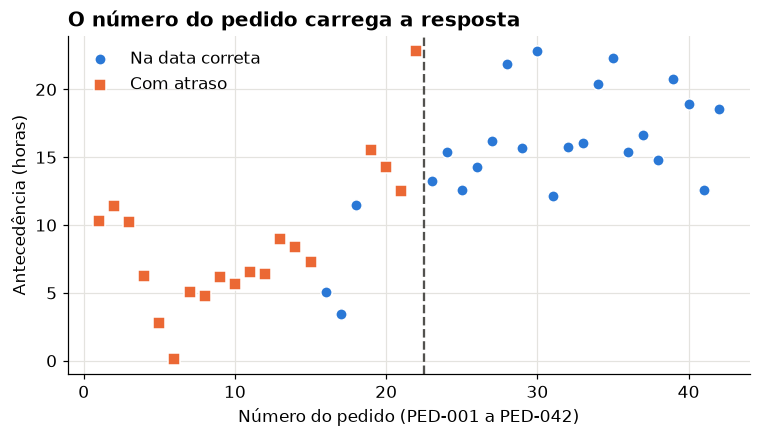

In [5]:
def melhor_corte(v, alvo):
    """Melhor regra 'v >= c prevê 1', testando todos os cortes entre valores vizinhos."""
    u = np.sort(np.unique(v))
    cortes = np.r_[u[0] - 1, (u[:-1] + u[1:]) / 2, u[-1] + 1]
    acertos = [int(((v >= c).astype(int) == alvo).sum()) for c in cortes]
    i = int(np.argmax(acertos))
    return cortes[i], acertos[i]

corte_id, acertos_id = melhor_corte(df["id"].values, y)
print("y na ordem do pedido:", "".join(df.sort_values("id")["y"].astype(str)))
print(f"Spearman id × y: {stats.spearmanr(df['id'], y).statistic:.3f}")
print(f"melhor corte no id: id ≥ {corte_id:.1f} acerta {acertos_id}/{n}")
print("melhor corte em x : x ≥ %.3f acerta %d/%d" % (*melhor_corte(x, y), n))

fig, ax = plt.subplots(figsize=(8, 4))
for classe, nome, cor, marca in CLASSES:
    sel = df["y"] == classe
    ax.scatter(df.loc[sel, "id"], df.loc[sel, "x"], s=55, color=cor, marker=marca, edgecolor="white", label=nome)
ax.axvline(corte_id, color=COR_APOIO, linestyle="--")
ax.set(xlabel="Número do pedido (PED-001 a PED-042)", ylabel="Antecedência (horas)",
       title="O número do pedido carrega a resposta")
ax.legend(loc="upper left")
plt.show()

**O número do pedido acerta mais que a antecedência** (39 contra 36 de 42). É um *vazamento*: uma
coluna que carrega a resposta sem explicar nada. Um modelo que a usasse pareceria melhor e não serviria
para um pedido novo, por isso ela fica de fora. A explicação provável (hipótese) é que a tabela foi
montada em blocos (15 atrasos, 3 acertos, 4 atrasos, 20 acertos) e depois embaralhada.

---
# 4. Visualização antes do ajuste

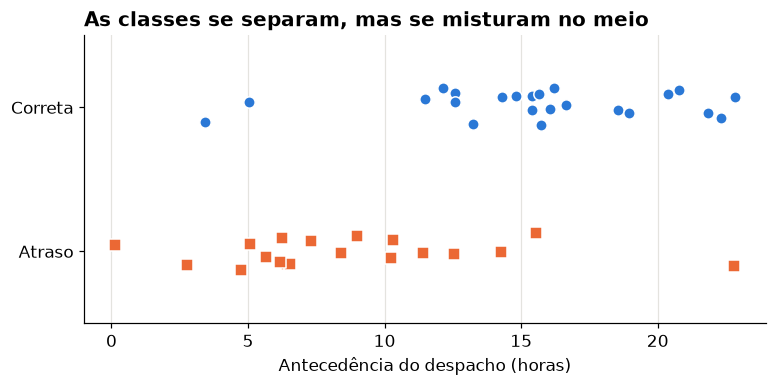

In [6]:
# O deslocamento vertical (jitter) só separa pontos próximos; não carrega informação.
rng = np.random.default_rng(42)
fig, ax = plt.subplots(figsize=(8, 3.4))
for classe, nome, cor, marca in CLASSES:
    sel = y == classe
    ax.scatter(x[sel], classe + rng.uniform(-0.14, 0.14, sel.sum()), s=55, color=cor, marker=marca,
               edgecolor="white", label=f"{nome} (n = {sel.sum()})")
ax.set_yticks([0, 1], ["Atraso", "Correta"])
ax.set_ylim(-0.5, 1.5)
ax.grid(axis="y", visible=False)
ax.set(xlabel="Antecedência do despacho (horas)", title="As classes se separam, mas se misturam no meio")
plt.show()

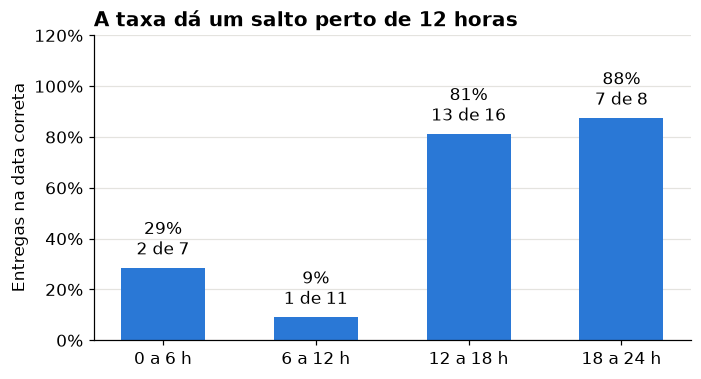

,pedidos,corretas,taxa
x,,,
0 a 6 h,7,2,0.2857
6 a 12 h,11,1,0.0909
12 a 18 h,16,13,0.8125
18 a 24 h,8,7,0.8750


In [7]:
# A taxa de entrega correta por faixa é uma primeira estimativa de p(x), sem modelo nenhum.
faixa = pd.cut(df["x"], bins=[0, 6, 12, 18, 24], right=False,
               labels=["0 a 6 h", "6 a 12 h", "12 a 18 h", "18 a 24 h"])
taxa = df.groupby(faixa, observed=False)["y"].agg(pedidos="size", corretas="sum")
taxa["taxa"] = taxa["corretas"] / taxa["pedidos"]

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(taxa.index.astype(str), taxa["taxa"], width=0.55, color=COR_CORRETA)
for i, (c, t, tx) in enumerate(zip(taxa["corretas"], taxa["pedidos"], taxa["taxa"])):
    ax.text(i, tx + 0.03, f"{tx:.0%}\n{c} de {t}", ha="center", va="bottom")
ax.set_ylim(0, 1.2)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.grid(axis="x", visible=False)
ax.set(ylabel="Entregas na data correta", title="A taxa dá um salto perto de 12 horas")
plt.show()
taxa

A subida não é gradual: a taxa fica baixa até 12 h e salta para 81%. A faixa de 0 a 6 h ainda fica
acima da de 6 a 12 h, por conta de 2 pedidos em 7.

### Por que a reta não serve

Ajustando a reta de mínimos quadrados direto nos 0/1:

ŷ = -0.0462 + 0.0478·x
em x = 0  → -0.046   (probabilidade negativa)
em x = 24 → 1.101   (probabilidade acima de 1)


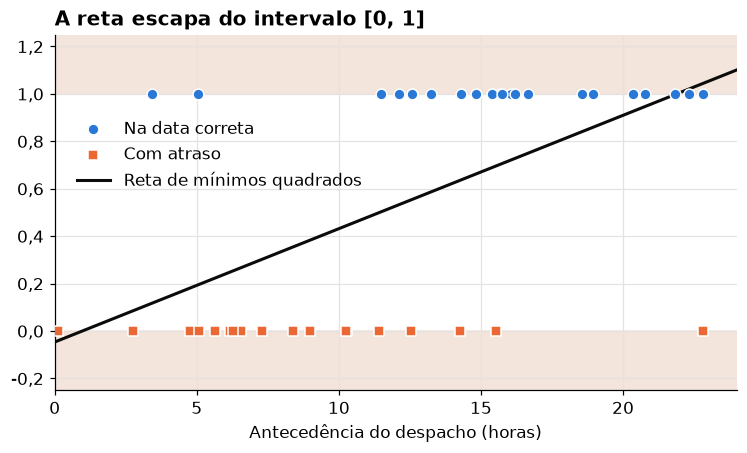

In [8]:
b1_reta = np.dot(x - x.mean(), y - y.mean()) / np.dot(x - x.mean(), x - x.mean())
b0_reta = y.mean() - b1_reta * x.mean()
print(f"ŷ = {b0_reta:.4f} + {b1_reta:.4f}·x")
print(f"em x = 0  → {b0_reta:.3f}   (probabilidade negativa)")
print(f"em x = 24 → {b0_reta + 24 * b1_reta:.3f}   (probabilidade acima de 1)")

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.axhspan(1, 1.25, color="#f3e4dc", zorder=0)
ax.axhspan(-0.25, 0, color="#f3e4dc", zorder=0)
for classe, nome, cor, marca in CLASSES:
    sel = y == classe
    ax.scatter(x[sel], y[sel], s=50, color=cor, marker=marca, edgecolor="white", label=nome, zorder=3)
ax.plot([0, 24], [b0_reta, b0_reta + 24 * b1_reta], color=COR_MODELO, lw=2, label="Reta de mínimos quadrados")
ax.set(xlim=(0, 24), ylim=(-0.25, 1.25), xlabel="Antecedência do despacho (horas)",
       title="A reta escapa do intervalo [0, 1]")
ax.yaxis.set_major_formatter(virgula(1))
ax.legend(loc="upper left", bbox_to_anchor=(0.01, 0.8))
plt.show()

Dois problemas: a reta é ilimitada e sai de $[0, 1]$; e a variância de uma Bernoulli é $p(1-p)$, que
muda com $x$, o que derruba a hipótese de variância constante da regressão linear.

---
# 5. Ajuste da regressão logística

### De onde vem a sigmoide

Precisamos de algo que vá de $-\infty$ a $+\infty$ para igualar a uma reta:

$$p \in (0,1) \;\longrightarrow\; \frac{p}{1-p} \in (0,\infty) \;\longrightarrow\; \ln\frac{p}{1-p} \in (-\infty,\infty)$$

Igualando o log da chance à reta $Z(x) = \beta_0 + \beta_1 x$ e isolando $p$:

$$\ln\frac{p}{1-p} = Z \quad\Longrightarrow\quad p = \frac{1}{1 + e^{-Z}}$$

### a) O que é otimizar

Cada pedido é uma Bernoulli; com pedidos independentes, a probabilidade da amostra é um produto, e o
logaritmo o troca por uma soma. Otimizar é maximizar a **log-verossimilhança**:

$$\ell(\beta) = \sum_{i=1}^{n} \big[\, y_i \ln p_i + (1 - y_i)\ln(1 - p_i) \,\big]$$

Com $dp/dZ = p(1-p)$ e $C = [\,1 \;\; x\,]$, o gradiente e a hessiana são:

$$\nabla \ell = C^T (y - p) \qquad H = -\,C^T W C, \quad W = \mathrm{diag}\big(p_i(1 - p_i)\big)$$

Como $p$ não é linear em $\beta$, $\nabla\ell = 0$ não vira um sistema linear: **não existe fórmula
fechada**. Mas $H$ é negativa definida, então $\ell$ é côncava e tem um único topo. Dois jeitos de subir:

$$\underbrace{\beta \leftarrow \beta + \alpha\, C^T(y - p)}_{\text{subida de gradiente}} \qquad\qquad \underbrace{\beta \leftarrow \beta + (C^T W C)^{-1} C^T (y - p)}_{\text{Newton-Raphson}}$$

In [9]:
def sigmoide(z):
    """σ(z) = 1 / (1 + e^(−z))."""
    return 1.0 / (1.0 + np.exp(-z))

def matriz_c(x):
    """C = [1 x]: a coluna de 1 multiplica β₀ (ordem do enunciado: β₀, β₁)."""
    return np.column_stack([np.ones(len(x)), x])

def log_verossimilhanca(beta, C, y):
    """ℓ(β) escrita como Σ[y·Z − ln(1 + e^Z)]: mesma função, sem calcular ln(0)."""
    Z = C @ beta
    return float(np.sum(y * Z - np.logaddexp(0, Z)))

def gradiente(beta, C, y):
    """∇ℓ = Cᵀ(y − p)."""
    return C.T @ (y - sigmoide(C @ beta))

def hessiana(beta, C):
    """H = −CᵀWC, com W = diag(p(1 − p))."""
    p = sigmoide(C @ beta)
    return -(C.T * (p * (1 - p))) @ C

def ajustar_newton(x, y, tol=1e-10, max_iter=100):
    """Newton-Raphson a partir de β = 0. Devolve (β, trajetória)."""
    C = matriz_c(x)
    beta = np.zeros(2)
    trajetoria = [beta.copy()]
    for _ in range(max_iter):
        passo = np.linalg.solve(-hessiana(beta, C), gradiente(beta, C, y))
        beta = beta + passo
        trajetoria.append(beta.copy())
        if np.max(np.abs(passo)) < tol:
            break
    return beta, np.array(trajetoria)

def ajustar_gradiente(x, y, alfa=0.0008, tol=1e-6, max_iter=2_000_000):
    """Subida de gradiente a partir de β = 0. α < 2/λ_max ≈ 0,001 (escala de x² em CᵀC)."""
    C = matriz_c(x)
    beta = np.zeros(2)
    trajetoria = [beta.copy()]
    for i in range(1, max_iter + 1):
        g = gradiente(beta, C, y)
        beta = beta + alfa * g
        if i <= 200 or i % 200 == 0:
            trajetoria.append(beta.copy())
        if np.max(np.abs(g)) < tol:
            break
    return beta, np.array(trajetoria), i

def prever_p(valores_x, beta):
    """p(x) para um escalar ou array de antecedências."""
    return sigmoide(beta[0] + beta[1] * np.asarray(valores_x, dtype=float))

In [10]:
C = matriz_c(x)
beta, traj_newton = ajustar_newton(x, y)
b0, b1 = beta
p = sigmoide(C @ beta)

iteracoes = pd.DataFrame({"β₀": traj_newton[:, 0], "β₁": traj_newton[:, 1],
                          "ℓ(β)": [log_verossimilhanca(b, C, y) for b in traj_newton]})
iteracoes.index.name = "iteração de Newton"
iteracoes.style.format("{:.8f}")

,β₀,β₁,ℓ(β)
iteração de Newton,,,
0,0.00000000,0.00000000,-29.11218158
1,-2.18492951,0.19119052,-21.51194413
2,-2.84541601,0.25023898,-21.09916670
3,-2.96648319,0.26104509,-21.08963557
4,-2.97004225,0.26136028,-21.08962807
5,-2.97004519,0.26136054,-21.08962807
6,-2.97004519,0.26136054,-21.08962807


Newton             : 6 iterações
Subida de gradiente: 19887 iterações, β = (-2.970044, 0.261360)


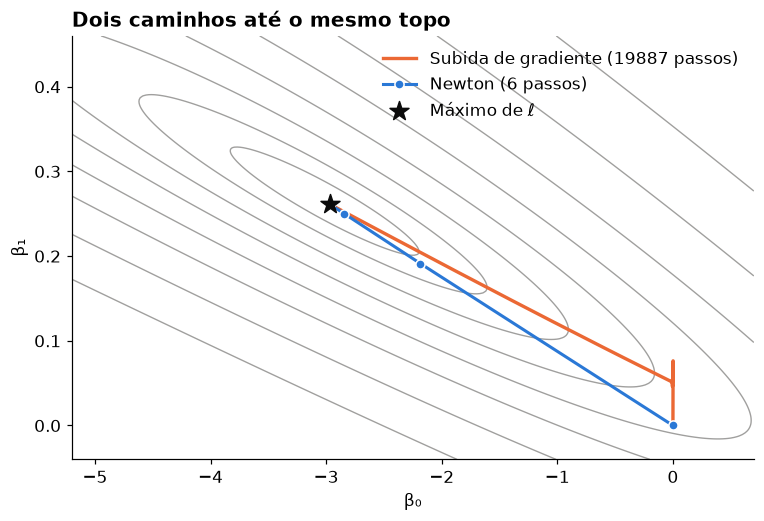

In [11]:
beta_gd, traj_gd, iter_gd = ajustar_gradiente(x, y)
print(f"Newton             : {len(traj_newton) - 1} iterações")
print(f"Subida de gradiente: {iter_gd} iterações, β = ({beta_gd[0]:.6f}, {beta_gd[1]:.6f})")

B0, B1 = np.meshgrid(np.linspace(-5.2, 0.7, 240), np.linspace(-0.04, 0.46, 240))
Z3 = B0[..., None] + B1[..., None] * x
ELL = np.sum(y * Z3 - np.logaddexp(0, Z3), axis=-1)
ell_max = log_verossimilhanca(beta, C, y)

fig, ax = plt.subplots(figsize=(8, 5))
ax.contour(B0, B1, ELL, levels=np.sort(ell_max - np.array([40, 25, 15, 9, 5, 2.5, 1, 0.3])),
           colors=COR_APOIO, linewidths=0.9, alpha=0.55, linestyles="solid")
ax.plot(traj_gd[:, 0], traj_gd[:, 1], color=COR_ATRASO, lw=2.2, label=f"Subida de gradiente ({iter_gd} passos)")
ax.plot(traj_newton[:, 0], traj_newton[:, 1], color=COR_CORRETA, lw=2, marker="o",
        markeredgecolor="white", label=f"Newton ({len(traj_newton) - 1} passos)")
ax.scatter([b0], [b1], s=170, marker="*", color=COR_MODELO, zorder=5, label="Máximo de ℓ")
ax.grid(False)
ax.set(xlabel="β₀", ylabel="β₁", title="Dois caminhos até o mesmo topo")
ax.legend(loc="upper right")
plt.show()

Os dois chegam ao mesmo ponto. A subida de gradiente só conhece a inclinação e precisa de passo
pequeno, porque $x^2$ dentro de $C^TC$ deixa a superfície muito mais íngreme numa direção que na outra.
Newton usa também a curvatura.

**Ponte com a forma matricial vista em aula:** cada passo de Newton resolve
$(C^TWC)\,\Delta = C^T(y - p)$, o sistema $C^TC\beta = C^Ty$ dos mínimos quadrados com pesos (IRLS).
Saindo de $\beta = 0$, todo $p_i = 1/2$ e todo peso vale $1/4$, e o primeiro passo é
$\beta^{(1)} = 4\,(C^TC)^{-1}C^T(y - 1/2)$: **quatro vezes a reta de mínimos quadrados** em $y - 1/2$.

### Verificações

Nenhuma compara com um valor esperado; cada uma confere uma identidade matemática.

In [12]:
def derivada_numerica(f, b, h=1e-6):
    return np.array([(f(b + h * e) - f(b - h * e)) / (2 * h) for e in np.eye(2)])

teste = np.array([-1.0, 0.1])
z = np.linspace(-6, 6, 25)
sk_sem_pen = LogisticRegression(C=np.inf, tol=1e-10, max_iter=10_000).fit(x.reshape(-1, 1), y)

verificacoes = {
    "V1  σ(0) = 1/2  e  σ(−z) = 1 − σ(z)":
        sigmoide(0.0) == 0.5 and np.allclose(sigmoide(-z), 1 - sigmoide(z)),
    "V2  gradiente analítico = derivada numérica de ℓ":
        np.allclose(gradiente(teste, C, y), derivada_numerica(lambda b: log_verossimilhanca(b, C, y), teste), atol=1e-5),
    "V3  hessiana analítica = derivada numérica do gradiente":
        np.allclose(hessiana(teste, C), np.column_stack(
            [derivada_numerica(lambda b, k=k: gradiente(b, C, y)[k], teste) for k in range(2)]), atol=1e-4),
    "V4  equações de escore no ótimo: Σ(y − p) ≈ 0  e  Σx(y − p) ≈ 0":
        np.allclose(gradiente(beta, C, y), 0, atol=1e-9),
    "V5  hessiana negativa definida (ℓ é côncava: o topo é único)":
        np.all(np.linalg.eigvalsh(hessiana(beta, C)) < 0),
    "V6  subida de gradiente chega ao mesmo β de Newton":
        np.allclose(beta, beta_gd, atol=1e-5),
    "V7  coincide com sklearn LogisticRegression(C=np.inf)":
        np.allclose(beta, [sk_sem_pen.intercept_[0], sk_sem_pen.coef_[0, 0]], atol=1e-5),
    "V8  1º passo de Newton = 4 × reta de mínimos quadrados em y − 1/2":
        np.allclose(traj_newton[1], 4 * np.linalg.solve(C.T @ C, C.T @ (y - 0.5))),
}
for nome, ok in verificacoes.items():
    print(f"  [{'OK' if ok else 'FALHA'}]  {nome}")
print(f"\n{sum(verificacoes.values())}/{len(verificacoes)} verificações")
assert all(verificacoes.values())
print(f"Consequência da V4: Σp = {p.sum():.6f} = Σy = {y.sum()}")

  [OK]  V1  σ(0) = 1/2  e  σ(−z) = 1 − σ(z)
  [OK]  V2  gradiente analítico = derivada numérica de ℓ
  [OK]  V3  hessiana analítica = derivada numérica do gradiente
  [OK]  V4  equações de escore no ótimo: Σ(y − p) ≈ 0  e  Σx(y − p) ≈ 0
  [OK]  V5  hessiana negativa definida (ℓ é côncava: o topo é único)
  [OK]  V6  subida de gradiente chega ao mesmo β de Newton
  [OK]  V7  coincide com sklearn LogisticRegression(C=np.inf)
  [OK]  V8  1º passo de Newton = 4 × reta de mínimos quadrados em y − 1/2

8/8 verificações
Consequência da V4: Σp = 23.000000 = Σy = 23


In [13]:
# O padrão do sklearn aplica regularização L2 (C = 1) e não devolve a máxima verossimilhança.
# C é o INVERSO da força da penalidade: C = np.inf a desliga.
sk_padrao = LogisticRegression().fit(x.reshape(-1, 1), y)
pd.DataFrame({"β₀": [b0, sk_sem_pen.intercept_[0], sk_padrao.intercept_[0]],
              "β₁": [b1, sk_sem_pen.coef_[0, 0], sk_padrao.coef_[0, 0]]},
             index=["à mão (máxima verossimilhança)", "sklearn C=np.inf", "sklearn padrão (C=1, L2)"]
            ).style.format("{:.6f}")

,β₀,β₁
à mão (máxima verossimilhança),-2.970045,0.261361
sklearn C=np.inf,-2.970045,0.261361
"sklearn padrão (C=1, L2)",-2.949310,0.259623


### b) Coeficientes e funções

$$Z(x) = -2{,}9700 + 0{,}2614\,x \qquad\qquad p(x) = \frac{1}{1 + e^{-(-2{,}9700 \,+\, 0{,}2614\,x)}}$$

### c) Interpretação do sinal de $\beta_1$

$\hat\beta_1 > 0$: a probabilidade de entrega na data correta **aumenta** com a antecedência. Como
$\ln(\text{chance}) = Z$, cada hora soma $\beta_1$ ao log da chance, ou seja, **multiplica a chance
por $e^{\beta_1}$**. A célula abaixo calcula esse fator, sua incerteza e o teste contra o modelo sem $x$.

In [14]:
ep = np.sqrt(np.diag(np.linalg.inv(-hessiana(beta, C))))      # Var(β̂) ≈ (CᵀWC)⁻¹
ic_b1 = b1 + np.array([-1, 1]) * stats.norm.ppf(0.975) * ep[1]

ell = log_verossimilhanca(beta, C, y)
p_nulo = y.mean()
ell_nulo = float(np.sum(y * np.log(p_nulo) + (1 - y) * np.log(1 - p_nulo)))
D = 2 * (ell - ell_nulo)

print(f"Z(x) = {b0:.4f} + {b1:.4f}·x")
print(f"β₁ = {b1:.4f} > 0 → a probabilidade de entrega correta AUMENTA com a antecedência")
print(f"erro padrão de β₁ : {ep[1]:.4f}   IC 95%: [{ic_b1[0]:.4f}, {ic_b1[1]:.4f}]")
print(f"razão de chances  : e^β₁ = {np.exp(b1):.4f}   IC 95%: [{np.exp(ic_b1[0]):.3f}, {np.exp(ic_b1[1]):.3f}]")
print(f"p(x) = 0,5 em     : x = −β₀/β₁ = {-b0 / b1:.3f} h")
print(f"inclinação máxima : β₁/4 = {b1 / 4:.4f} por hora")
print(f"razão de verossimilhança: D = {D:.3f}, p = {stats.chi2.sf(D, df=1):.2e}")
print(f"R² de McFadden    : {1 - ell / ell_nulo:.3f}")

Z(x) = -2.9700 + 0.2614·x
β₁ = 0.2614 > 0 → a probabilidade de entrega correta AUMENTA com a antecedência
erro padrão de β₁ : 0.0823   IC 95%: [0.1001, 0.4226]
razão de chances  : e^β₁ = 1.2987   IC 95%: [1.105, 1.526]
p(x) = 0,5 em     : x = −β₀/β₁ = 11.364 h
inclinação máxima : β₁/4 = 0.0653 por hora
razão de verossimilhança: D = 15.664, p = 7.57e-05
R² de McFadden    : 0.271


- **O efeito é constante na chance, não na probabilidade.** Cada hora multiplica a chance por 1,30; a
  probabilidade sobe no máximo 6,5 pontos por hora, e só perto de 11,4 h.
- **$\hat\beta_0 = -2{,}97$** é o log da chance em $x = 0$: $p(0) \approx 4{,}9\%$ para quem despacha em
  cima do prazo.
- **O efeito é real, mas a estimativa é larga:** $p \approx 7{,}6 \cdot 10^{-5}$ no teste de razão de
  verossimilhança, mas o fator por hora fica entre 1,10 e 1,53 com 42 pedidos.

### d) e e) Probabilidades para 5, 10, 15 e 20 horas

In [15]:
horas = np.array([5, 10, 15, 20])
Zh = b0 + b1 * horas
pd.DataFrame({"Z(x)": Zh, "chance e^Z": np.exp(Zh), "P(Y=1|x)": sigmoide(Zh), "P(Y=0|x) = 1 − p(x)": 1 - sigmoide(Zh)},
             index=pd.Index(horas, name="antecedência (h)"))

,Z(x),chance e^Z,P(Y=1|x),P(Y=0|x) = 1 − p(x)
antecedência (h),,,,
5,-1.6632,0.1895,0.1593,0.8407
10,-0.3564,0.7002,0.4118,0.5882
15,0.9504,2.5866,0.7212,0.2788
20,2.2572,9.5560,0.9053,0.0947


Cada 5 horas multiplicam a chance por $e^{5\beta_1} \approx 3{,}7$ (coluna "chance"). A probabilidade
não segue esse ritmo: sobe 25, 31 e 18 pontos percentuais, mais rápido no meio da curva.

**Sensibilidade:** quanto um único pedido pesa no coeficiente?

In [16]:
i_estranho = int(np.argmax(np.where(y == 0, x, -np.inf)))     # o atraso de maior antecedência
sem = np.arange(n) != i_estranho
beta_sem, _ = ajustar_newton(x[sem], y[sem])
print(f"{df['pedido'].iloc[i_estranho]}: atraso com x = {x[i_estranho]} h, para o qual o modelo dava p = {p[i_estranho]:.3f}")
print(f"sem ele: β₁ = {beta_sem[1]:.4f} ({beta_sem[1] / b1 - 1:+.1%})")

PED-022: atraso com x = 22.81 h, para o qual o modelo dava p = 0.952
sem ele: β₁ = 0.3538 (+35.4%)


---
# 6. Classificação, limiar e curva logística

A regra é $\hat y = 1$ se $p(x) \ge t$. A acurácia é uma **escada**: só muda quando $t$ cruza a
probabilidade de algum pedido. Então não se deriva, se enumera: com $n$ pedidos há no máximo $n + 1$
classificações diferentes, e testar cada $p_i$ como limiar cobre todas. O máximo é sempre uma **faixa**
de limiares; adota-se o ponto médio dela.

In [17]:
def classificar(p, t):
    """ŷ = 1 se p ≥ t."""
    return (p >= t).astype(int)

def varrer_limiares(p, y):
    """Todos os limiares que mudam algo: os pᵢ ordenados, mais um acima de 1."""
    candidatos = np.r_[np.sort(np.unique(p)), 1.0 + 1e-9]
    acertos = np.array([(classificar(p, t) == y).sum() for t in candidatos])
    return candidatos, acertos

def logit(t):
    return np.log(t / (1 - t))

def inverter(t, beta):
    """x* tal que p(x*) = t."""
    return (logit(t) - beta[0]) / beta[1]

candidatos, acertos = varrer_limiares(p, y)
k = int(np.argmax(acertos))
assert (acertos == acertos[k]).sum() == 1          # um único degrau ótimo
t_inf, t_sup = candidatos[k - 1], candidatos[k]
LIMIAR = (t_inf + t_sup) / 2
X_CORTE = inverter(LIMIAR, beta)
y_hat = classificar(p, LIMIAR)

print(f"{len(candidatos)} classificações possíveis para {n} pedidos")
print(f"acertos em t = 0,5 : {(classificar(p, 0.5) == y).sum()}/{n}")
print(f"melhor resultado   : {acertos[k]}/{n} = {acertos[k] / n:.4f}")
print(f"degrau ótimo       : t ∈ ({t_inf:.4f}, {t_sup:.4f}]   largura {t_sup - t_inf:.4f}")
print(f"limiar adotado     : t* = {LIMIAR:.4f} (ponto médio)")

print("\nUma grade comum passa por cima do degrau?")
for passo in [0.1, 0.05, 0.01, 0.005, 0.001]:
    grade = np.round(np.arange(0, 1 + passo / 2, passo), 6)
    print(f"  passo {passo:<6}: melhor {max((classificar(p, t) == y).sum() for t in grade)}/{n}")

43 classificações possíveis para 42 pedidos
acertos em t = 0,5 : 35/42
melhor resultado   : 36/42 = 0.8571
degrau ótimo       : t ∈ (0.5037, 0.5082]   largura 0.0046
limiar adotado     : t* = 0.5060 (ponto médio)

Uma grade comum passa por cima do degrau?
  passo 0.1   : melhor 35/42
  passo 0.05  : melhor 35/42
  passo 0.01  : melhor 35/42
  passo 0.005 : melhor 36/42
  passo 0.001 : melhor 36/42


### Inversão da função logística

$$t = \frac{1}{1 + e^{-Z}} \;\Longrightarrow\; Z = \ln\frac{t}{1 - t} \;\Longrightarrow\; x^{\ast} = \frac{\ln\frac{t}{1-t} - \beta_0}{\beta_1}$$

Como $p(x)$ é crescente, "$p(x) \ge t$" e "$x \ge x^{\ast}$" são a mesma regra: o modelo vira uma linha de
corte em horas.

In [18]:
print(f"logit(t*) = {logit(LIMIAR):.4f}")
print(f"x* = (logit(t*) − β₀)/β₁ = ({logit(LIMIAR):.4f} + {-b0:.4f}) / {b1:.4f} = {X_CORTE:.3f} h")
print(f"o degrau em horas: x* ∈ ({inverter(t_inf, beta):.3f}, {inverter(t_sup, beta):.3f}]")
assert np.isclose(prever_p(X_CORTE, beta), LIMIAR)          # ida e volta
assert np.array_equal(y_hat, (x >= X_CORTE).astype(int))     # p ≥ t*  ⇔  x ≥ x*
print("conferido: p(x*) = t*  e  'p ≥ t*' classifica igual a 'x ≥ x*'")

print(f"\nem t = 0,5 o corte seria x = {inverter(0.5, beta):.3f} h; a diferença está em um pedido:")
df.assign(p=p)[classificar(p, 0.5) != y_hat]

logit(t*) = 0.0238
x* = (logit(t*) − β₀)/β₁ = (0.0238 + 2.9700) / 0.2614 = 11.455 h
o degrau em horas: x* ∈ (11.420, 11.490]
conferido: p(x*) = t*  e  'p ≥ t*' classifica igual a 'x ≥ x*'

em t = 0,5 o corte seria x = 11.364 h; a diferença está em um pedido:


,pedido,x,y,id,p
12,PED-002,11.4200,0,2,0.5037


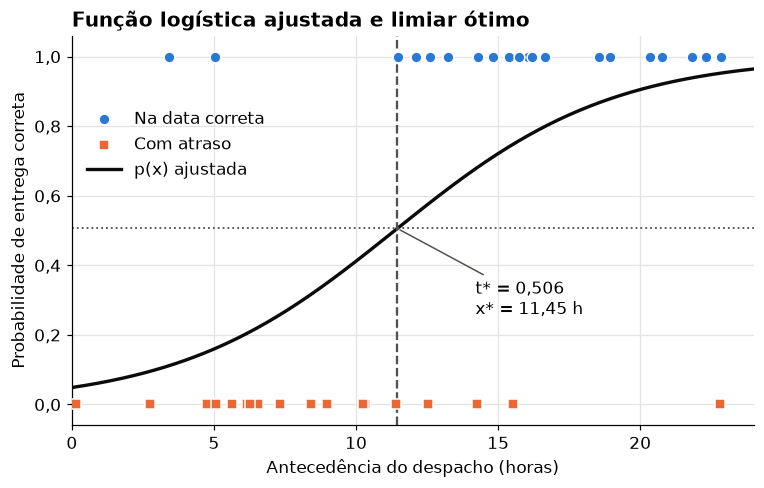

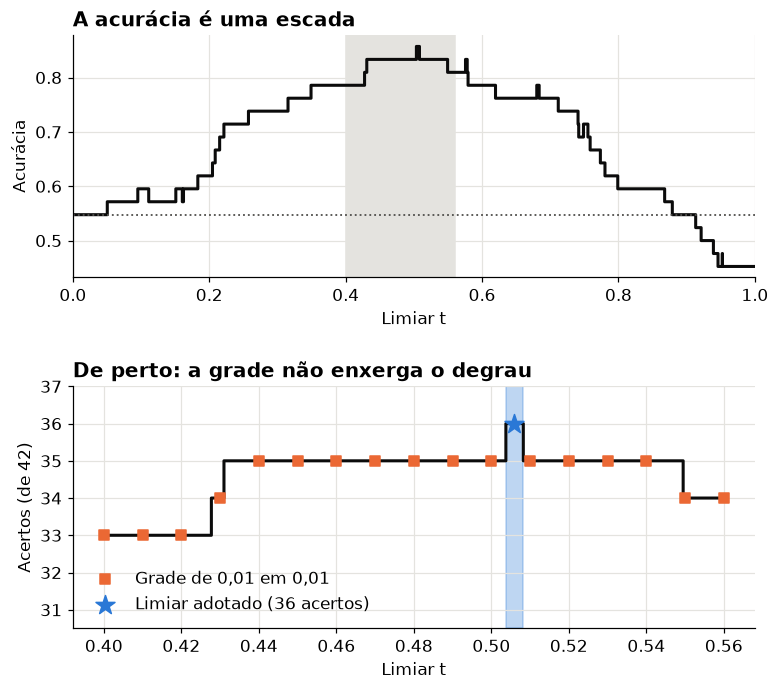

In [19]:
grade_x = np.linspace(0, 24, 400)
fig, ax = plt.subplots(figsize=(8, 4.6))
for classe, nome, cor, marca in CLASSES:
    sel = y == classe
    ax.scatter(x[sel], y[sel], s=50, color=cor, marker=marca, edgecolor="white", label=nome, zorder=3)
ax.plot(grade_x, prever_p(grade_x, beta), color=COR_MODELO, lw=2.2, label="p(x) ajustada")
ax.axhline(LIMIAR, color=COR_APOIO, lw=1.2, linestyle=":")
ax.axvline(X_CORTE, color=COR_APOIO, lw=1.5, linestyle="--")
ax.annotate(f"t* = {LIMIAR:.3f}\nx* = {X_CORTE:.2f} h".replace(".", ","), xy=(X_CORTE, LIMIAR), xytext=(14.2, 0.26),
            arrowprops=dict(arrowstyle="-", color=COR_APOIO))
ax.set(xlim=(0, 24), ylim=(-0.06, 1.06), xlabel="Antecedência do despacho (horas)",
       ylabel="Probabilidade de entrega correta", title="Função logística ajustada e limiar ótimo")
ax.yaxis.set_major_formatter(virgula(1))
ax.legend(loc="center left", bbox_to_anchor=(0.0, 0.72))
plt.show()

ts = np.linspace(0, 1, 4001)
acc = np.array([(classificar(p, t) == y).mean() for t in ts])
zoom = (ts >= 0.40) & (ts <= 0.56)
grade01 = np.round(np.arange(0.40, 0.561, 0.01), 2)
fig, (a1, a2) = plt.subplots(2, 1, figsize=(8, 7), gridspec_kw={"hspace": 0.45})
a1.step(ts, acc, where="post", color=COR_MODELO, lw=2)
a1.axhline(y.mean(), color=COR_APOIO, lw=1.2, linestyle=":")
a1.axvspan(0.40, 0.56, color=COR_GRADE, zorder=0)
a1.set(xlim=(0, 1), xlabel="Limiar t", ylabel="Acurácia", title="A acurácia é uma escada")
a2.step(ts[zoom], acc[zoom] * n, where="post", color=COR_MODELO, lw=2)
a2.scatter(grade01, [(classificar(p, t) == y).sum() for t in grade01], s=45, color=COR_ATRASO, marker="s",
           zorder=4, label="Grade de 0,01 em 0,01")
a2.axvspan(t_inf, t_sup, color=COR_CORRETA, alpha=0.3, zorder=0)
a2.scatter([LIMIAR], [acertos[k]], s=170, marker="*", color=COR_CORRETA, zorder=5, label=f"Limiar adotado ({acertos[k]} acertos)")
a2.set(ylim=(acertos[k] - 5.5, acertos[k] + 1), xlabel="Limiar t", ylabel="Acertos (de 42)",
       title="De perto: a grade não enxerga o degrau")
a2.legend(loc="lower left")
plt.show()

O degrau ótimo tem só 0,0046 de largura: uma busca de 0,01 em 0,01 passa por cima dele. O corte em
**11,45 h** fica entre o PED-002 (11,42 h, atraso) e o PED-018 (11,49 h, entrega correta), e o ganho sobre
$t = 0{,}5$ é de **um pedido**.

---
# 7. Matriz de confusão

Classe positiva: entrega na data correta. FP = o modelo prometeu no prazo e o pedido atrasou;
FN = o modelo previu atraso e o pedido chegou no prazo.

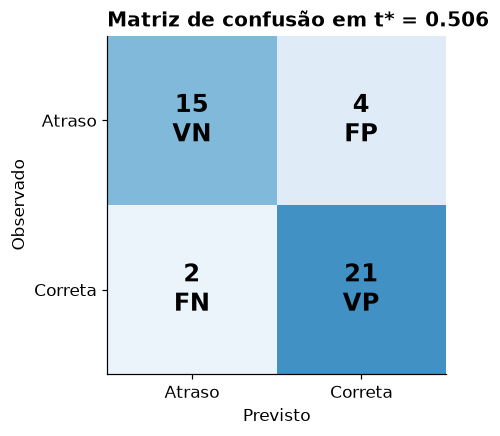

conferida com sklearn.metrics.confusion_matrix
Os erros:


,pedido,x,y,id,p,previsto
10,PED-017,3.4100,1,17,0.1112,0
29,PED-016,5.0300,1,16,0.1604,0
40,PED-021,12.5300,0,21,0.5756,1
36,PED-020,14.2500,0,20,0.6801,1
26,PED-019,15.5400,0,19,0.7487,1
35,PED-022,22.8100,0,22,0.9522,1


In [20]:
def matriz_confusao(y, y_hat):
    """Devolve VN, FP, FN, VP."""
    return (int(((y == 0) & (y_hat == 0)).sum()), int(((y == 0) & (y_hat == 1)).sum()),
            int(((y == 1) & (y_hat == 0)).sum()), int(((y == 1) & (y_hat == 1)).sum()))

vn, fp, fn, vp = matriz_confusao(y, y_hat)
assert skm.confusion_matrix(y, y_hat).tolist() == [[vn, fp], [fn, vp]]

M = np.array([[vn, fp], [fn, vp]])
fig, ax = plt.subplots(figsize=(4.8, 4))
ax.imshow(M, cmap="Blues", vmin=0, vmax=M.max() * 1.6)
for i, linha in enumerate([["VN", "FP"], ["FN", "VP"]]):
    for j, rotulo in enumerate(linha):
        ax.text(j, i, f"{M[i, j]}\n{rotulo}", ha="center", va="center", fontsize=16, fontweight="bold")
ax.set_xticks([0, 1], ["Atraso", "Correta"])
ax.set_yticks([0, 1], ["Atraso", "Correta"])
ax.set(xlabel="Previsto", ylabel="Observado", title=f"Matriz de confusão em t* = {LIMIAR:.3f}")
ax.grid(False)
plt.show()

print("conferida com sklearn.metrics.confusion_matrix\nOs erros:")
df.assign(p=p, previsto=y_hat)[y_hat != y].sort_values("x")

---
# 8. Métricas

$$\text{Acurácia} = \frac{VP + VN}{n} \quad \text{Precisão} = \frac{VP}{VP + FP} \quad \text{Recall} = \frac{VP}{VP + FN} \quad \text{Especificidade} = \frac{VN}{VN + FP} \quad F_1 = \frac{2PR}{P + R}$$

O enunciado escreve "Previsão da classe positiva"; foi usada a fórmula da **precisão**.

In [21]:
def metricas(y, y_hat):
    vn, fp, fn, vp = matriz_confusao(y, y_hat)
    precisao, recall = vp / (vp + fp), vp / (vp + fn)
    return {"Acurácia": (vp + vn) / len(y), "Precisão": precisao, "Recall": recall,
            "Especificidade": vn / (vn + fp), "F1": 2 * precisao * recall / (precisao + recall)}

m = metricas(y, y_hat)
assert np.isclose(m["F1"], 2 * vp / (2 * vp + fp + fn))                  # F1 não tem VN
assert np.isclose(m["Acurácia"], skm.accuracy_score(y, y_hat))
assert np.isclose(m["Precisão"], skm.precision_score(y, y_hat))
assert np.isclose(m["Recall"], skm.recall_score(y, y_hat))
assert np.isclose(m["Especificidade"], skm.recall_score(y, y_hat, pos_label=0))
assert np.isclose(m["F1"], skm.f1_score(y, y_hat))
print("conferido: as cinco métricas batem com sklearn.metrics")

pd.DataFrame({"t* = %.4f" % LIMIAR: m, "t = 0,5": metricas(y, classificar(p, 0.5))})

conferido: as cinco métricas batem com sklearn.metrics


,t* = 0.5060,"t = 0,5"
Acurácia,0.8571,0.8333
Precisão,0.8400,0.8077
Recall,0.9130,0.9130
Especificidade,0.7895,0.7368
F1,0.8750,0.8571


In [22]:
def wilson(acertos, total, confianca=0.95):
    """Intervalo de Wilson para uma proporção (adequado a n pequeno)."""
    z = stats.norm.ppf(0.5 + confianca / 2)
    phat = acertos / total
    den = 1 + z ** 2 / total
    centro = (phat + z ** 2 / (2 * total)) / den
    raio = z * np.sqrt(phat * (1 - phat) / total + z ** 2 / (4 * total ** 2)) / den
    return centro - raio, centro + raio

base = max(y.mean(), 1 - y.mean())
ic = wilson(vp + vn, n)
print(f"sempre prever a classe mais comum: {base:.4f}")
print(f"modelo                           : {m['Acurácia']:.4f}   (ganho {m['Acurácia'] - base:+.4f})")
print(f"IC 95% de Wilson da acurácia     : [{ic[0]:.3f}, {ic[1]:.3f}]")

sempre prever a classe mais comum: 0.5476
modelo                           : 0.8571   (ganho +0.3095)
IC 95% de Wilson da acurácia     : [0.722, 0.933]


- **Recall 91% contra especificidade 79%:** o modelo acha melhor as entregas certas que os atrasos.
  Para a transportadora, é a especificidade que dói: 21% dos atrasos passam como se fossem chegar no prazo.
- **O F1 não enxerga os verdadeiros negativos** ($2VP/(2VP + FP + FN)$ não tem $VN$), por isso a
  especificidade vem ao lado.

### Quanto dessa acurácia sobrevive a um pedido novo

O modelo e o limiar foram escolhidos olhando os mesmos 42 pedidos em que foram avaliados. O
*leave-one-out* tira um pedido, refaz tudo com os outros 41 (β **e** limiar) e prevê o que ficou de fora.

In [23]:
loo_otimo = np.zeros(n, dtype=int)
loo_05 = np.zeros(n, dtype=int)
for i in range(n):
    fora = np.arange(n) != i
    b, _ = ajustar_newton(x[fora], y[fora])
    cand, ac = varrer_limiares(prever_p(x[fora], b), y[fora])
    j = int(np.argmax(ac))
    t = ((cand[j - 1] if j > 0 else 0.0) + cand[j]) / 2
    p_i = prever_p(x[i], b)
    loo_otimo[i], loo_05[i] = int(p_i >= t), int(p_i >= 0.5)

pd.DataFrame({"na amostra, t*": m, "leave-one-out, limiar otimizado": metricas(y, loo_otimo),
              "leave-one-out, t = 0,5": metricas(y, loo_05)})

,"na amostra, t*","leave-one-out, limiar otimizado","leave-one-out, t = 0,5"
Acurácia,0.8571,0.8095,0.8095
Precisão,0.8400,0.8000,0.8000
Recall,0.9130,0.8696,0.8696
Especificidade,0.7895,0.7368,0.7368
F1,0.8750,0.8333,0.8333


Fora da amostra, o modelo acerta **34 de 42 (81%)**, e otimizar o limiar não ganhou nada sobre 0,5:
aquele pedido a mais era ajuste à amostra. Esta é a razão do "inicialmente, utilize os 42 registros
para um ajuste didático" do enunciado.

### Curva ROC (extra, do cronograma da IC)

A área sob a curva tem uma leitura exata: a probabilidade de que, sorteando um pedido correto e um
atrasado, o modelo dê $p$ maior ao correto (estatística de Mann-Whitney normalizada).

AUC = 0.842105  (trapézios = pares = Mann-Whitney = sklearn)


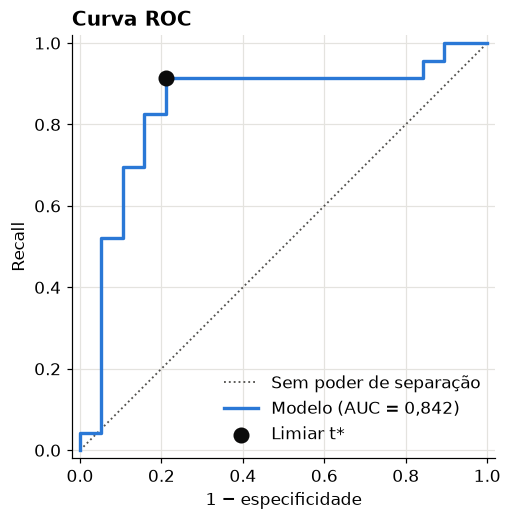

In [24]:
limiares = np.r_[np.inf, np.sort(np.unique(p))[::-1]]
fpr = np.array([((p >= t) & (y == 0)).sum() / (y == 0).sum() for t in limiares])
tpr = np.array([((p >= t) & (y == 1)).sum() / (y == 1).sum() for t in limiares])

auc_trap = float(np.sum(np.diff(fpr) * (tpr[1:] + tpr[:-1]) / 2))
dif = p[y == 1][:, None] - p[y == 0][None, :]
auc_pares = float(((dif > 0).sum() + 0.5 * (dif == 0).sum()) / dif.size)
auc_mw = stats.mannwhitneyu(p[y == 1], p[y == 0]).statistic / (y.sum() * (n - y.sum()))
assert np.isclose(auc_trap, auc_pares) and np.isclose(auc_pares, auc_mw)
assert np.isclose(auc_trap, skm.roc_auc_score(y, p))
print(f"AUC = {auc_trap:.6f}  (trapézios = pares = Mann-Whitney = sklearn)")

fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0, 1], [0, 1], color=COR_APOIO, lw=1.2, linestyle=":", label="Sem poder de separação")
ax.step(fpr, tpr, where="post", color=COR_CORRETA, lw=2.2, label=f"Modelo (AUC = {auc_trap:.3f})".replace(".", ","))
ax.scatter([fp / (fp + vn)], [vp / (vp + fn)], s=90, color=COR_MODELO, zorder=4, label="Limiar t*")
ax.set(xlim=(-0.02, 1.02), ylim=(-0.02, 1.02), aspect="equal", title="Curva ROC",
       xlabel="1 − especificidade", ylabel="Recall")
ax.legend(loc="lower right")
plt.show()

### Calibração por faixa

A primeira equação de escore garante que $\sum p_i = \sum y_i$ no total. As faixas mostram onde a
curva suave erra.

In [25]:
calib = df.assign(p=p).groupby(faixa, observed=False).agg(
    pedidos=("y", "size"), corretas_previstas=("p", "sum"), corretas_observadas=("y", "sum"),
    p_medio=("p", "mean"), taxa_observada=("y", "mean"))
assert np.isclose(calib["corretas_previstas"].sum(), calib["corretas_observadas"].sum())
calib

,pedidos,corretas_previstas,corretas_observadas,p_medio,taxa_observada
x,,,,,
0 a 6 h,7,0.9131,2,0.1304,0.2857
6 a 12 h,11,3.6421,1,0.3311,0.0909
12 a 18 h,16,11.0742,13,0.6921,0.8125
18 a 24 h,8,7.3706,7,0.9213,0.8750


A logística é suave, e os dados saltam perto de 12 h: o modelo superestima de 6 a 12 h e subestima de
12 a 18 h. A forma da curva é uma hipótese do modelo, que 42 pedidos não confirmam nem descartam.

---
# Conclusão e recomendação

A acurácia conta um FP e um FN como o mesmo erro. Para a operação eles não são iguais, e subir o
limiar troca um pelo outro:

In [26]:
linhas = {}
for t in [LIMIAR, 0.7, 0.8, 0.9]:
    prev = classificar(p, t)
    vn_t, fp_t, fn_t, vp_t = matriz_confusao(y, prev)
    linhas[f"t = {t:.3f}"] = {"corte (h)": inverter(t, beta), "VN": vn_t, "FP": fp_t, "FN": fn_t, "VP": vp_t,
                             **metricas(y, prev)}
pd.DataFrame(linhas).T

,corte (h),VN,FP,FN,VP,Acurácia,Precisão,Recall,Especificidade,F1
t = 0.506,11.4550,15.0000,4.0000,2.0000,21.0000,0.8571,0.8400,0.9130,0.7895,0.8750
t = 0.700,14.6057,17.0000,2.0000,8.0000,15.0000,0.7619,0.8824,0.6522,0.8947,0.7500
t = 0.800,16.6679,18.0000,1.0000,16.0000,7.0000,0.5952,0.8750,0.3043,0.9474,0.4516
t = 0.900,19.7707,18.0000,1.0000,18.0000,5.0000,0.5476,0.8333,0.2174,0.9474,0.3448


1. **A antecedência ajuda a prever o prazo.** O efeito é claro ($p \approx 7{,}6 \cdot 10^{-5}$), mas o
   tamanho é incerto: cada hora multiplica a chance por algo entre 1,10 e 1,53.
2. **Despachos com menos de ~11,5 horas de antecedência devem ser tratados como risco.** Abaixo desse
   corte, só 2 de 17 pedidos chegaram na data correta; acima, 21 de 25.
3. **Para prometer prazo com mais segurança, ~15 horas é um ponto razoável:** em 14,61 h, o limiar 0,70
   deixa 2 atrasos passarem em vez de 4. Acima de 16,67 h resta sempre o mesmo atraso, o PED-022.
4. **O limiar final depende de custo, não de acurácia.** Se prometer e atrasar custa mais do que
   sinalizar risco à toa, o limiar sobe.
5. **Espera-se ~81% de acurácia em pedidos novos**, não 85,7%.

**Hipóteses declaradas:** o modelo mostra associação, não causa (rota, distância e tipo de carga podem
explicar as duas coisas). Os dados são didáticos, com 42 pedidos e uma única variável.